# 🌍 Clasificador de país con ResNet18 — World StreetView 500k (streaming + Colab free T4)

Entrena una **ResNet18 preentrenada (ImageNet)** para predecir el **país** (`country_code`) de cada imagen de Street View, leyendo el dataset de Hugging Face **en streaming** (no se descargan los ~198 GB).

**Cómo usarlo**
1. `Entorno de ejecución → Cambiar tipo de entorno → T4 GPU`.
2. (Opcional pero recomendado) poné tu token de HF en la celda de configuración, o guardalo en *Secrets* (🔑) con el nombre `HF_TOKEN`.
3. Ejecutá las celdas de la sección **Setup** y después la celda de **Entrenamiento**.
4. **Si Colab se corta**: `Entorno de ejecución → Ejecutar todo` (o las celdas de Setup + la de Entrenamiento). Retoma solo desde el último checkpoint en tu Drive.
5. Las celdas de **Métricas** se pueden correr en cualquier momento (usan el mejor checkpoint) — también con el entrenamiento a medias.

**Decisiones de diseño (todas configurables en la celda de CFG)**
- Cada imagen es una muestra (las 4 vistas N/S/E/O de una ubicación se tratan como imágenes independientes). Imágenes **sin país válido se ignoran**.
- **Sin flip horizontal** como augmentation: invertiría el lado de la ruta (mano izquierda/derecha), que es una pista clave para identificar país.
- Validación con el split `val` de 3000 imágenes (ubicaciones disjuntas de train). Se cachea en tu Drive.
- Entrenamiento con AMP fp16, `channels_last`, decodificación JPEG reducida (`draft`) y preprocesado en workers; augmentation liviana en GPU.
- Una *época* = una pasada completa del train (~2M imágenes). En el plan gratuito probablemente completes 1–2 épocas, así que el scheduler de LR está planificado para `EPOCHS` (podés bajarlo).

## 1) Setup

In [ ]:
!pip -q install -U datasets huggingface_hub pycountry pycountry_convert plotly psutil

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
import os, io, json, time, math, random, gc, warnings
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount("/content/drive")

# ----------------- Token de Hugging Face -----------------
# El dataset es público, pero con token el streaming tiene mejores límites de uso.
HF_TOKEN = ""   # <-- COMPLETAR (hf_xxx...). Alternativa: Colab -> Secrets -> HF_TOKEN
if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
HF_TOKEN = HF_TOKEN or None


class CFG:
    REPO = "josefbednar/world-streetview-500k"
    PROJECT_DIR = "/content/drive/MyDrive/streetview_country_resnet18"   # todo se guarda acá

    # --- datos ---
    IMG_SIZE = 192            # 160 = más rápido / 224 = más preciso y más lento
    MIN_CLASS_IMAGES = 50     # países con menos imágenes en train se ignoran (no se pueden aprender)
    NUM_WORKERS = 2           # Colab free tiene 2 vCPU y ~12 GB de RAM; más workers = más RAM, no más velocidad
    SHUFFLE_BUFFER = 512      # imágenes (bytes JPEG) mezcladas por worker; ~60-100 MB
    PREFETCH = 2              # batches por adelantado por worker
    ROW_BATCH = 64            # filas que lee pyarrow por vez del parquet

    # --- entrenamiento ---
    EPOCHS = 6
    BATCH_SIZE = 128
    LR_BACKBONE = 4e-4
    LR_HEAD = 2e-3
    WEIGHT_DECAY = 0.01
    LABEL_SMOOTHING = 0.1
    WARMUP_FRAC = 0.03
    CLASS_WEIGHT_POWER = 0.5  # 0 = sin pesos | 0.5 = inverso de raíz de frecuencia | 1 = balanceo total
    GPU_AUG = True            # brillo/contraste aleatorio en GPU (sin flip)
    MAX_STEPS_PER_EPOCH = None  # ej. 300 para una prueba rápida de punta a punta
    MAX_RUN_HOURS = None        # ej. 10 -> corta prolijo y guarda antes del límite de Colab

    # --- checkpoints / logs ---
    SAVE_EVERY_STEPS = 500
    EVAL_EVERY_STEPS = 2000
    LOG_EVERY = 100
    SEED = 42


DIR = Path(CFG.PROJECT_DIR)
CKPT_DIR = DIR / "checkpoints"
OUT_DIR = DIR / "outputs"
for p in (DIR, CKPT_DIR, OUT_DIR):
    p.mkdir(parents=True, exist_ok=True)

random.seed(CFG.SEED); np.random.seed(CFG.SEED); torch.manual_seed(CFG.SEED)
assert torch.cuda.is_available(), "Activá la GPU: Entorno de ejecución → Cambiar tipo de entorno → T4 GPU"
device = torch.device("cuda")
torch.backends.cudnn.benchmark = True
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)
print("Drive:", DIR)

Mounted at /content/drive
GPU: Tesla T4 | torch 2.11.0+cu130
Drive: /content/drive/MyDrive/streetview_country_resnet18


### Metadata de países (una sola vez, queda cacheada en Drive)
Lee **solo 3 columnas** (`country_code`, `latitude`, `longitude`) de los 393 parquets con *range requests* (no baja las imágenes). Sirve para definir las clases, contar imágenes por país (pesos de clase, pasos por época) y calcular el centroide de cada país (para las métricas de distancia).

In [ ]:
from huggingface_hub import HfApi, HfFileSystem
import pyarrow.parquet as pq
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm

def valid_cc(cc):
    return isinstance(cc, str) and len(cc.strip()) == 2 and cc.strip().isalpha()

def norm_cc(cc):
    return cc.strip().upper()

META_PATH = DIR / "meta.json"

def _file_stats(path, retries=4):
    for attempt in range(retries):
        try:
            fs = HfFileSystem(token=HF_TOKEN)
            with fs.open(f"datasets/{CFG.REPO}/{path}", "rb") as f:
                df = pq.ParquetFile(f).read(columns=["country_code", "latitude", "longitude"]).to_pandas()
            break
        except Exception:
            if attempt == retries - 1:
                raise
            time.sleep(2 * (attempt + 1))
    n_rows = len(df)
    df = df[df["country_code"].map(valid_cc)].copy()
    df["cc"] = df["country_code"].str.strip().str.upper()
    lat = np.radians(np.nan_to_num(df["latitude"].astype(float).values))
    lon = np.radians(np.nan_to_num(df["longitude"].astype(float).values))
    df["x"] = np.cos(lat) * np.cos(lon); df["y"] = np.cos(lat) * np.sin(lon); df["z"] = np.sin(lat)
    g = df.groupby("cc").agg(n=("cc", "size"), x=("x", "sum"), y=("y", "sum"), z=("z", "sum"))
    return n_rows, g

def build_meta():
    api = HfApi(token=HF_TOKEN)
    files = sorted(f for f in api.list_repo_files(CFG.REPO, repo_type="dataset")
                   if f.endswith(".parquet") and os.path.basename(f).startswith("train-"))
    assert files, "No encontré parquets 'train-*' en el repo."
    total_rows, agg = 0, None
    with ThreadPoolExecutor(8) as ex:
        futs = [ex.submit(_file_stats, f) for f in files]
        for fu in tqdm(as_completed(futs), total=len(futs), desc="leyendo metadata"):
            n_rows, g = fu.result()
            total_rows += n_rows
            agg = g if agg is None else agg.add(g, fill_value=0)
    with_country = int(agg["n"].sum())
    keep = agg[agg["n"] >= CFG.MIN_CLASS_IMAGES].sort_index()
    cent = {}
    for cc, r in keep.iterrows():
        v = np.array([r["x"], r["y"], r["z"]]); v = v / (np.linalg.norm(v) + 1e-12)
        cent[cc] = [float(np.degrees(np.arcsin(np.clip(v[2], -1, 1)))), float(np.degrees(np.arctan2(v[1], v[0])))]
    meta = dict(
        classes=list(keep.index), counts={cc: int(keep.loc[cc, "n"]) for cc in keep.index}, centroids=cent,
        total_rows=int(total_rows), rows_with_country=with_country, rows_used=int(keep["n"].sum()),
        min_class_images=CFG.MIN_CLASS_IMAGES, n_files=len(files))
    json.dump(meta, open(META_PATH, "w"))
    return meta

meta = json.load(open(META_PATH)) if META_PATH.exists() else None
if meta is None or meta.get("min_class_images") != CFG.MIN_CLASS_IMAGES:
    meta = build_meta()

classes = meta["classes"]
class2idx = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)
counts = np.array([meta["counts"][c] for c in classes], dtype=np.int64)
cent_lat = np.array([meta["centroids"][c][0] for c in classes]); cent_lon = np.array([meta["centroids"][c][1] for c in classes])
N_TRAIN = meta["rows_used"]

print(f"Filas totales train: {meta['total_rows']:,}")
print(f"  sin país válido (se ignoran): {meta['total_rows'] - meta['rows_with_country']:,}")
print(f"  de países con < {CFG.MIN_CLASS_IMAGES} imágenes (se ignoran): {meta['rows_with_country'] - N_TRAIN:,}")
print(f"  usadas para entrenar: {N_TRAIN:,}  |  clases (países): {n_classes}")
print("Top 10 países:", sorted(meta["counts"].items(), key=lambda kv: -kv[1])[:10])

Filas totales train: 1,999,060
  sin país válido (se ignoran): 7,932
  de países con < 50 imágenes (se ignoran): 236
  usadas para entrenar: 1,990,892  |  clases (países): 101
Top 10 países: [('US', 476840), ('IN', 266860), ('BR', 136920), ('FR', 86208), ('CA', 63792), ('AU', 61304), ('RU', 55884), ('TH', 52776), ('ID', 48156), ('JP', 45736)]


In [ ]:
# ----- Info por país: nombre, continente, ISO3 -----
import pycountry, pycountry_convert as pcc

CONT_NAMES = {"AF": "África", "AS": "Asia", "EU": "Europa", "NA": "Norteamérica",
              "SA": "Sudamérica", "OC": "Oceanía", "AN": "Antártida", "??": "Desconocido"}
CONT_OVERRIDE = {"XK": "EU", "TL": "AS", "VA": "EU"}

def cont_code(cc):
    if cc in CONT_OVERRIDE:
        return CONT_OVERRIDE[cc]
    try:
        return pcc.country_alpha2_to_continent_code(cc)
    except Exception:
        return "??"

def iso3(cc):
    if cc == "XK":
        return "XKX"
    try:
        return pycountry.countries.get(alpha_2=cc).alpha_3
    except Exception:
        return None

def cname(cc):
    try:
        return pycountry.countries.get(alpha_2=cc).name
    except Exception:
        return cc

class_info = pd.DataFrame({
    "idx": range(n_classes), "cc": classes, "name": [cname(c) for c in classes],
    "continent": [cont_code(c) for c in classes], "iso3": [iso3(c) for c in classes],
    "n_train": counts, "lat": cent_lat, "lon": cent_lon})
cont_of = class_info["continent"].values
print(class_info.groupby("continent").agg(paises=("cc", "size"), imagenes=("n_train", "sum")).rename(index=CONT_NAMES))
if (class_info["continent"] == "??").any():
    print("⚠️ Sin continente:", class_info.loc[class_info["continent"] == "??", "cc"].tolist())

              paises  imagenes
continent                     
África            13     49648
Asia              29    546268
Europa            40    528036
Norteamérica       8    590304
Oceanía            2     70820
Sudamérica         9    205816


### Imágenes: decodificación rápida + caché de validación
`decode_img` usa `draft` de PIL: el JPEG se decodifica ya reducido (mucho más rápido que decodificar completo y redimensionar).
El split `val` (3000 imágenes) se decodifica **una vez** y se guarda en tu Drive.

In [ ]:
from datasets import load_dataset, Image as HFImage
from PIL import Image as PILImage

def decode_img(b, size):
    im = PILImage.open(io.BytesIO(b))
    try:
        im.draft("RGB", (size, size))        # decodificación JPEG reducida
    except Exception:
        pass
    im = im.convert("RGB").resize((size, size), PILImage.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

VAL_CACHE = DIR / f"val_cache_{CFG.IMG_SIZE}.pt"

def build_val_cache():
    ds = load_dataset(CFG.REPO, split="val", streaming=True, token=HF_TOKEN)
    ds = ds.cast_column("image", HFImage(decode=False))
    imgs, ys, rows, skipped = [], [], [], 0
    for ex in tqdm(ds, desc="cacheando val"):
        cc = ex["country_code"]
        if not valid_cc(cc) or norm_cc(cc) not in class2idx:
            skipped += 1; continue
        try:
            imgs.append(decode_img(ex["image"]["bytes"], CFG.IMG_SIZE))
        except Exception:
            skipped += 1; continue
        ys.append(class2idx[norm_cc(cc)])
        rows.append((ex["panoid"], float(ex["latitude"]), float(ex["longitude"]), norm_cc(cc)))
    print(f"val: {len(ys)} imágenes usadas, {skipped} ignoradas (sin país / país fuera de las clases / error de decodificación)")
    d = {"x": torch.from_numpy(np.stack(imgs)), "y": torch.tensor(ys), "meta": rows, "classes": classes}
    torch.save(d, VAL_CACHE)
    return d

VAL = torch.load(VAL_CACHE, weights_only=False) if VAL_CACHE.exists() else None
if VAL is None or VAL["classes"] != classes:
    VAL = build_val_cache()
print("val cache:", tuple(VAL["x"].shape), "(N, H, W, 3) uint8")

val cache: (2996, 192, 192, 3) (N, H, W, 3) uint8


### Dataset en streaming, modelo y utilidades
- Lector propio con `pyarrow`: lee los parquets de HF **un row group por vez** (memoria acotada, sin la maquinaria de `datasets`) y entrega bytes JPEG crudos; la **decodificación se hace en los workers** (`collate_fn`).
- Para retomar, el checkpoint guarda **hasta qué fila se consumió de cada archivo** en la época; al volver se saltea lo ya visto. Se pierden a lo sumo unos cientos de muestras (las que estaban en el buffer de mezcla).
- El log muestra el **% de RAM**: si se acerca a 85–90%, bajá `NUM_WORKERS`, `SHUFFLE_BUFFER` o `BATCH_SIZE`.

In [ ]:
import psutil
from torch.utils.data import DataLoader, IterableDataset, get_worker_info

def ram_pct():
    return psutil.virtual_memory().percent

# Lista de parquets de train (solo nombres, no baja nada)
TRAIN_FILES = sorted(f for f in HfApi(token=HF_TOKEN).list_repo_files(CFG.REPO, repo_type="dataset")
                     if f.endswith(".parquet") and os.path.basename(f).startswith("train-"))
if len(TRAIN_FILES) != meta["n_files"]:
    print(f"⚠️ meta.json se armó con {meta['n_files']} parquets y ahora hay {len(TRAIN_FILES)}")
print(f"{len(TRAIN_FILES)} parquets de train | RAM usada ahora: {ram_pct():.0f}%")


class ParquetStream(IterableDataset):
    """Lee los parquets de HF con pyarrow, un row group por vez, en streaming.
    - Cada worker toma archivos distintos (orden mezclado por época).
    - Ignora filas sin país válido / fuera de las clases.
    - `progress` = {archivo: próxima fila} para retomar sin repetir lo ya visto.
    Memoria por worker ≈ 1 row group + SHUFFLE_BUFFER imágenes JPEG (bytes)."""

    def __init__(self, files, epoch, progress=None, salt=0):
        self.files, self.epoch, self.salt = files, epoch, salt
        self.progress = dict(progress or {})
        self.order = list(range(len(files)))
        random.Random(CFG.SEED + epoch).shuffle(self.order)

    def _read(self, fs, fidx, start):
        with fs.open(f"datasets/{CFG.REPO}/{self.files[fidx]}", "rb") as f:
            pf = pq.ParquetFile(f, pre_buffer=False)
            md = pf.metadata; base = 0
            for rg in range(md.num_row_groups):
                n = md.row_group(rg).num_rows
                if base + n <= start:          # row group ya consumido
                    base += n; continue
                row = base
                for b in pf.iter_batches(batch_size=CFG.ROW_BATCH, row_groups=[rg],
                                         columns=["image", "country_code"], use_threads=False):
                    imgs = b.column("image").to_pylist(); ccs = b.column("country_code").to_pylist()
                    for im, cc in zip(imgs, ccs):
                        if row >= start and im and im.get("bytes") and valid_cc(cc) and norm_cc(cc) in class2idx:
                            yield im["bytes"], class2idx[norm_cc(cc)], fidx, row
                        row += 1
                base += n

    def _file_rows(self, fs, fidx):
        start, tries = self.progress.get(fidx, 0), 0
        while True:
            try:
                for item in self._read(fs, fidx, start):
                    start = item[3] + 1
                    yield item
                return
            except Exception as e:             # cortes de red: reintenta desde la última fila leída
                tries += 1
                if tries > 4:
                    print(f"⚠️ salteo {self.files[fidx]} desde la fila {start}: {type(e).__name__}: {e}")
                    return
                time.sleep(3 * tries)

    def __iter__(self):
        wi = get_worker_info(); wid, nw = (wi.id, wi.num_workers) if wi else (0, 1)
        fs = HfFileSystem(token=HF_TOKEN)
        rng = random.Random(CFG.SEED * 7919 + self.epoch * 131 + wid + 1000 * self.salt)
        buf = []
        for fidx in self.order[wid::nw]:
            for item in self._file_rows(fs, fidx):
                if len(buf) < CFG.SHUFFLE_BUFFER:
                    buf.append(item); continue
                j = rng.randrange(len(buf)); yield buf[j]; buf[j] = item
        rng.shuffle(buf)
        yield from buf


def collate(batch):
    imgs, ys, fi, rw = [], [], [], []
    for byt, y, f, r in batch:
        fi.append(f); rw.append(r)             # el progreso cuenta aunque falle la decodificación
        try:
            imgs.append(decode_img(byt, CFG.IMG_SIZE)); ys.append(y)
        except Exception:
            continue
    fi, rw = torch.tensor(fi, dtype=torch.long), torch.tensor(rw, dtype=torch.long)
    if not imgs:
        return torch.empty(0, 3, CFG.IMG_SIZE, CFG.IMG_SIZE, dtype=torch.uint8), torch.empty(0, dtype=torch.long), fi, rw
    x = torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2)   # uint8 NCHW (strides channels_last)
    return x, torch.tensor(ys, dtype=torch.long), fi, rw

def update_progress(prog, fi, rw):
    fi, rw = fi.numpy(), rw.numpy()
    for f in np.unique(fi):
        m = int(rw[fi == f].max()) + 1
        if m > prog.get(int(f), 0):
            prog[int(f)] = m

def make_loader(ds):
    kw = dict(batch_size=CFG.BATCH_SIZE, num_workers=CFG.NUM_WORKERS, collate_fn=collate, pin_memory=True)
    if CFG.NUM_WORKERS > 0:
        kw["prefetch_factor"] = CFG.PREFETCH
    return DataLoader(ds, **kw)


MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255

def gpu_prep(x_uint8, train):
    x = x_uint8.to(device, non_blocking=True).float().contiguous(memory_format=torch.channels_last)
    if train and CFG.GPU_AUG:
        b = x.size(0)
        br = torch.rand(b, 1, 1, 1, device=device) * 0.4 + 0.8
        ct = torch.rand(b, 1, 1, 1, device=device) * 0.4 + 0.8
        m = x.mean(dim=(1, 2, 3), keepdim=True)
        x = (((x - m) * ct + m) * br).clamp_(0, 255)
    return (x - MEAN) / STD

def build_model(n_cls, pretrained=True):
    from torchvision.models import resnet18, ResNet18_Weights
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    m.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.fc.in_features, n_cls))
    return m

@torch.no_grad()
def predict_probs(model, X_nhwc, bs=250):
    model.eval(); out = []
    for i in range(0, len(X_nhwc), bs):
        xb = gpu_prep(X_nhwc[i:i + bs].permute(0, 3, 1, 2), False)
        with torch.autocast("cuda", dtype=torch.float16):
            lg = model(xb)
        out.append(F.softmax(lg.float(), 1).cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def evaluate(model, bs=250):
    model.eval()
    X, Y = VAL["x"], VAL["y"]; n = len(Y); tot, c1, c5 = 0.0, 0, 0
    for i in range(0, n, bs):
        xb = gpu_prep(X[i:i + bs].permute(0, 3, 1, 2), False); yb = Y[i:i + bs].to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            lg = model(xb)
        lg = lg.float(); tot += F.cross_entropy(lg, yb, reduction="sum").item()
        t5 = lg.topk(min(5, lg.size(1)), 1).indices
        c1 += (t5[:, 0] == yb).sum().item(); c5 += (t5 == yb[:, None]).any(1).sum().item()
    return dict(top1=c1 / n, top5=c5 / n, loss=tot / n)

# pesos de clase (media ponderada por muestra = 1, acotados para países muy raros)
w = (counts.max() / counts.astype(np.float64)) ** CFG.CLASS_WEIGHT_POWER
w = w / (w * counts).sum() * counts.sum()
cls_weights = torch.tensor(np.clip(w, 0.1, 10.0), dtype=torch.float32, device=device)
print("pesos de clase min/max:", float(cls_weights.min()), float(cls_weights.max()))

# prueba rápida del stream: baja un batch y CIERRA los workers (si no, siguen vivos ocupando RAM)
_t = time.time(); _ld = make_loader(ParquetStream(TRAIN_FILES, 0)); _it = iter(_ld); _x, _y, _f, _r = next(_it)
print(f"Batch de prueba OK: {tuple(_x.shape)} en {time.time()-_t:.1f}s | países en el batch: {len(set(_y.tolist()))} | RAM: {ram_pct():.0f}%")
del _it, _ld, _x, _y, _f, _r; gc.collect(); time.sleep(2)
print(f"RAM tras cerrar los workers: {ram_pct():.0f}%")

393 parquets de train | RAM usada ahora: 16%
pesos de clase min/max: 0.3004818260669708 10.0
Batch de prueba OK: (128, 3, 192, 192) en 8.4s | países en el batch: 26 | RAM: 26%
RAM tras cerrar los workers: 21%


## 2) Entrenamiento (con checkpoints y resume automático)

- Guarda en tu Drive cada `SAVE_EVERY_STEPS` pasos y al terminar cada época: `checkpoints/last.pt` (+ `last_prev.pt` de respaldo), `epoch_N.pt` (pesos), `best.pt` (mejor top-1 en val) e `history.json`.
- **Si se corta Colab: volvé a correr Setup + esta celda y sigue desde el último checkpoint.**
- Podés interrumpir la celda (■) y también guarda antes de salir.
- El log muestra `esperando datos`: si es alto (>30%), el cuello de botella es la red/CPU, no la GPU → bajá `IMG_SIZE` o subí `NUM_WORKERS`.

In [ ]:
def load_last():
    for name in ["last.pt", "last_prev.pt"]:
        p = CKPT_DIR / name
        if p.exists():
            try:
                return torch.load(p, map_location="cpu", weights_only=False), name
            except Exception as e:
                print(f"⚠️ No pude leer {name}: {e}")
    return None, None

def atomic_save(obj, name):
    tmp, dst = CKPT_DIR / (name + ".tmp"), CKPT_DIR / name
    torch.save(obj, tmp)
    os.replace(tmp, dst)

def run_training():
    spe = CFG.MAX_STEPS_PER_EPOCH or math.ceil(N_TRAIN / CFG.BATCH_SIZE)       # pasos por época
    total_steps = CFG.EPOCHS * spe; warm = max(1, int(CFG.WARMUP_FRAC * total_steps))
    def lr_mult(s):
        if s < warm:
            return (s + 1) / warm
        p = min(1.0, (s - warm) / max(1, total_steps - warm))
        return 0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * p))

    model = build_model(n_classes).to(device).to(memory_format=torch.channels_last)
    head_ids = {id(p) for p in model.fc.parameters()}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]; head = list(model.fc.parameters())
    groups = []
    for params, lr in ((backbone, CFG.LR_BACKBONE), (head, CFG.LR_HEAD)):
        groups.append({"params": [p for p in params if p.ndim > 1], "lr": lr, "base_lr": lr, "weight_decay": CFG.WEIGHT_DECAY})
        groups.append({"params": [p for p in params if p.ndim <= 1], "lr": lr, "base_lr": lr, "weight_decay": 0.0})
    try:
        opt = torch.optim.AdamW(groups, fused=True)
    except Exception:
        opt = torch.optim.AdamW(groups)
    scaler = torch.amp.GradScaler("cuda")

    epoch0, sie, gstep, best_val, resumes, train_secs, prog = 0, 0, 0, -1.0, 0, 0.0, {}
    hist = {"train": [], "val": []}
    st, which = load_last()
    if st is not None:
        assert st["classes"] == classes, "El checkpoint tiene otras clases que meta.json; borrá la carpeta checkpoints/ para empezar de cero."
        model.load_state_dict(st["model"]); opt.load_state_dict(st["opt"]); scaler.load_state_dict(st["scaler"])
        epoch0, sie, gstep = st["epoch"], st["step_in_epoch"], st["global_step"]
        best_val, hist, prog = st["best_val"], st["history"], dict(st.get("file_progress") or {})
        resumes, train_secs = st.get("resumes", 0) + 1, st.get("train_seconds", 0.0)
        print(f"♻️  Retomando desde {which}: época {epoch0+1}, paso {sie}/{spe} (global {gstep}), mejor val top-1 {best_val:.4f}, "
              f"tiempo de entrenamiento acumulado {train_secs/3600:.2f} h, {len(prog)} archivos ya tocados en esta época")
        if epoch0 >= CFG.EPOCHS:
            print("✅ El entrenamiento ya estaba completo."); return model
    else:
        print(f"🚀 Entrenamiento nuevo: {N_TRAIN:,} imágenes, {spe} pasos/época, {CFG.EPOCHS} épocas, batch {CFG.BATCH_SIZE}, img {CFG.IMG_SIZE}px")

    def save_ckpt(next_epoch, step_in_epoch, progress):
        state = dict(model=model.state_dict(), opt=opt.state_dict(), scaler=scaler.state_dict(), epoch=next_epoch,
                     step_in_epoch=step_in_epoch, global_step=gstep, best_val=best_val, history=hist, classes=classes,
                     file_progress=dict(progress), resumes=resumes, train_seconds=train_secs + (time.time() - t_start),
                     cfg={k: v for k, v in vars(CFG).items() if not k.startswith("_")})
        if (CKPT_DIR / "last.pt").exists():
            os.replace(CKPT_DIR / "last.pt", CKPT_DIR / "last_prev.pt")
        atomic_save(state, "last.pt")
        json.dump(hist, open(DIR / "history.json", "w"))

    t_start = time.time(); stop = False
    for epoch in range(epoch0, CFG.EPOCHS):
        ds = ParquetStream(TRAIN_FILES, epoch, prog, salt=resumes)
        loader = make_loader(ds)
        model.train(); it = iter(loader)
        a_loss = torch.zeros((), device=device); a_corr = torch.zeros((), device=device); a_n = 0
        t_wait, t_win = 0.0, time.time()
        try:
            while sie < spe:
                t0 = time.time()
                try:
                    x, y, fi, rw = next(it)
                except StopIteration:
                    break
                t_wait += time.time() - t0
                update_progress(prog, fi, rw)
                if x.size(0) < 8:
                    continue
                x = gpu_prep(x, True); y = y.to(device, non_blocking=True)
                m = lr_mult(gstep)
                for g in opt.param_groups:
                    g["lr"] = g["base_lr"] * m
                with torch.autocast("cuda", dtype=torch.float16):
                    logits = model(x)
                loss = F.cross_entropy(logits.float(), y, weight=cls_weights, label_smoothing=CFG.LABEL_SMOOTHING)
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update()
                gstep += 1; sie += 1
                n = y.size(0); a_loss += loss.detach() * n; a_corr += (logits.argmax(1) == y).sum(); a_n += n

                if gstep % CFG.LOG_EVERY == 0:
                    dt = time.time() - t_win; ips = a_n / dt
                    row = dict(step=gstep, epoch=epoch + 1, loss=a_loss.item() / a_n, acc=a_corr.item() / a_n,
                               lr=opt.param_groups[0]["lr"], img_s=ips, wait=t_wait / dt, ram=ram_pct())
                    hist["train"].append(row)
                    eta_h = (spe - sie) * (CFG.BATCH_SIZE / max(ips, 1e-9)) / 3600
                    print(f"ép {epoch+1}/{CFG.EPOCHS} | paso {sie}/{spe} | loss {row['loss']:.3f} | acc {row['acc']:.3f} | "
                          f"lr {row['lr']:.1e} | {ips:.0f} img/s | esperando datos {row['wait']:.0%} | RAM {row['ram']:.0f}% | falta ~{eta_h:.1f} h de época")
                    a_loss.zero_(); a_corr.zero_(); a_n = 0; t_wait, t_win = 0.0, time.time()
                    if CFG.MAX_RUN_HOURS and (time.time() - t_start) / 3600 > CFG.MAX_RUN_HOURS:
                        print("⏱️ Límite de tiempo alcanzado, guardando y saliendo."); stop = True; break
                if gstep % CFG.EVAL_EVERY_STEPS == 0:
                    ev = evaluate(model); model.train()
                    hist["val"].append(dict(step=gstep, epoch=epoch + 1, **ev))
                    print(f"   🔎 val: top-1 {ev['top1']:.4f} | top-5 {ev['top5']:.4f} | loss {ev['loss']:.3f}")
                    if ev["top1"] > best_val:
                        best_val = ev["top1"]
                        atomic_save(dict(model=model.state_dict(), classes=classes, val=ev, step=gstep, img_size=CFG.IMG_SIZE), "best.pt")
                if gstep % CFG.SAVE_EVERY_STEPS == 0:
                    save_ckpt(epoch, sie, prog); print(f"   💾 checkpoint (paso global {gstep})")
        except KeyboardInterrupt:
            print("⛔ Interrumpido: guardando checkpoint..."); stop = True

        if stop:
            save_ckpt(epoch, sie, prog); print("💾 Guardado. Volvé a correr esta celda para continuar."); return model

        # ---- fin de época ----
        ev = evaluate(model); model.train()
        hist["val"].append(dict(step=gstep, epoch=epoch + 1, **ev))
        print(f"✅ Fin de época {epoch+1}: val top-1 {ev['top1']:.4f} | top-5 {ev['top5']:.4f} | loss {ev['loss']:.3f}")
        if ev["top1"] > best_val:
            best_val = ev["top1"]
            atomic_save(dict(model=model.state_dict(), classes=classes, val=ev, step=gstep, img_size=CFG.IMG_SIZE), "best.pt")
        atomic_save(dict(model=model.state_dict(), classes=classes, val=ev, step=gstep, epoch=epoch + 1, img_size=CFG.IMG_SIZE), f"epoch_{epoch+1}.pt")
        sie = 0; prog.clear()
        save_ckpt(epoch + 1, 0, prog); print(f"💾 checkpoint de fin de época guardado")
        del loader, it; gc.collect()

    print("🏁 Entrenamiento completo.")
    return model

trained_model = run_training()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 104MB/s]


🚀 Entrenamiento nuevo: 1,990,892 imágenes, 15554 pasos/época, 6 épocas, batch 128, img 192px
ép 1/6 | paso 100/15554 | loss 6.430 | acc 0.079 | lr 1.4e-05 | 146 img/s | esperando datos 82% | RAM 35% | falta ~3.8 h de época
ép 1/6 | paso 200/15554 | loss 6.108 | acc 0.276 | lr 2.9e-05 | 213 img/s | esperando datos 86% | RAM 37% | falta ~2.6 h de época
ép 1/6 | paso 300/15554 | loss 5.848 | acc 0.340 | lr 4.3e-05 | 251 img/s | esperando datos 86% | RAM 36% | falta ~2.2 h de época
ép 1/6 | paso 400/15554 | loss 5.533 | acc 0.380 | lr 5.7e-05 | 240 img/s | esperando datos 86% | RAM 36% | falta ~2.2 h de época
ép 1/6 | paso 500/15554 | loss 5.286 | acc 0.410 | lr 7.1e-05 | 188 img/s | esperando datos 88% | RAM 36% | falta ~2.9 h de época
   💾 checkpoint (paso global 500)
ép 1/6 | paso 600/15554 | loss 5.154 | acc 0.427 | lr 8.6e-05 | 242 img/s | esperando datos 83% | RAM 37% | falta ~2.2 h de época
ép 1/6 | paso 700/15554 | loss 5.139 | acc 0.464 | lr 1.0e-04 | 242 img/s | esperando datos 8

'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/josefbednar/world-streetview-500k/resolve/main/data/train-00330-of-00393.parquet
Retrying in 1s [Retry 1/5].


ép 1/6 | paso 1600/15554 | loss 4.722 | acc 0.510 | lr 2.3e-04 | 163 img/s | esperando datos 88% | RAM 37% | falta ~3.0 h de época
ép 1/6 | paso 1700/15554 | loss 4.756 | acc 0.520 | lr 2.4e-04 | 193 img/s | esperando datos 88% | RAM 36% | falta ~2.5 h de época
ép 1/6 | paso 1800/15554 | loss 4.792 | acc 0.528 | lr 2.6e-04 | 191 img/s | esperando datos 88% | RAM 37% | falta ~2.6 h de época


'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/josefbednar/world-streetview-500k/resolve/main/data/train-00320-of-00393.parquet
Retrying in 1s [Retry 1/5].


... (6 outputs left out)

ép 1/6 | paso 11500/15554 | loss 4.094 | acc 0.668 | lr 3.9e-04 | 128 img/s | esperando datos 92% | RAM 38% | falta ~1.1 h de época
   💾 checkpoint (paso global 11500)
ép 1/6 | paso 11600/15554 | loss 4.031 | acc 0.667 | lr 3.9e-04 | 184 img/s | esperando datos 88% | RAM 38% | falta ~0.8 h de época
ép 1/6 | paso 11700/15554 | loss 4.058 | acc 0.673 | lr 3.9e-04 | 246 img/s | esperando datos 86% | RAM 38% | falta ~0.6 h de época
ép 1/6 | paso 11800/15554 | loss 4.004 | acc 0.677 | lr 3.9e-04 | 239 img/s | esperando datos 87% | RAM 38% | falta ~0.6 h de época
ép 1/6 | paso 11900/15554 | loss 3.968 | acc 0.674 | lr 3.9e-04 | 256 img/s | esperando datos 86% | RAM 38% | falta ~0.5 h de época
ép 1/6 | paso 12000/15554 | loss 4.049 | acc 0.666 | lr 3.9e-04 | 202 img/s | esperando datos 89% | RAM 38% | falta ~0.6 h de época
   🔎 val: top-1 0.6419 | top-5 0.8905 | loss 1.711
   💾 checkpoint (paso global 12000)
ép 1/6 | paso 12100/15554 | loss 4.104 | acc 0.665 | lr 3.9e-04 | 175 img/s | esperan

'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/josefbednar/world-streetview-500k/resolve/main/data/train-00353-of-00393.parquet
Retrying in 1s [Retry 1/5].


ép 1/6 | paso 12700/15554 | loss 4.015 | acc 0.686 | lr 3.9e-04 | 177 img/s | esperando datos 90% | RAM 38% | falta ~0.6 h de época
ép 1/6 | paso 12800/15554 | loss 3.998 | acc 0.683 | lr 3.9e-04 | 209 img/s | esperando datos 88% | RAM 38% | falta ~0.5 h de época
ép 1/6 | paso 12900/15554 | loss 3.932 | acc 0.683 | lr 3.9e-04 | 188 img/s | esperando datos 88% | RAM 38% | falta ~0.5 h de época
ép 1/6 | paso 13000/15554 | loss 4.046 | acc 0.685 | lr 3.9e-04 | 259 img/s | esperando datos 85% | RAM 38% | falta ~0.4 h de época
   💾 checkpoint (paso global 13000)
ép 1/6 | paso 13100/15554 | loss 4.002 | acc 0.676 | lr 3.9e-04 | 173 img/s | esperando datos 88% | RAM 38% | falta ~0.5 h de época
ép 1/6 | paso 13200/15554 | loss 4.007 | acc 0.664 | lr 3.9e-04 | 182 img/s | esperando datos 90% | RAM 38% | falta ~0.5 h de época
ép 1/6 | paso 13300/15554 | loss 4.024 | acc 0.683 | lr 3.9e-04 | 181 img/s | esperando datos 89% | RAM 38% | falta ~0.4 h de época
ép 1/6 | paso 13400/15554 | loss 4.007 |

KeyboardInterrupt: 

## 3) Métricas y análisis
Estas celdas usan el **mejor checkpoint** (`best.pt`, o `last.pt` si todavía no hay uno) y el split `val` cacheado. Se pueden correr con el entrenamiento a medias.
Todas las figuras se guardan también en `outputs/` dentro de tu Drive.

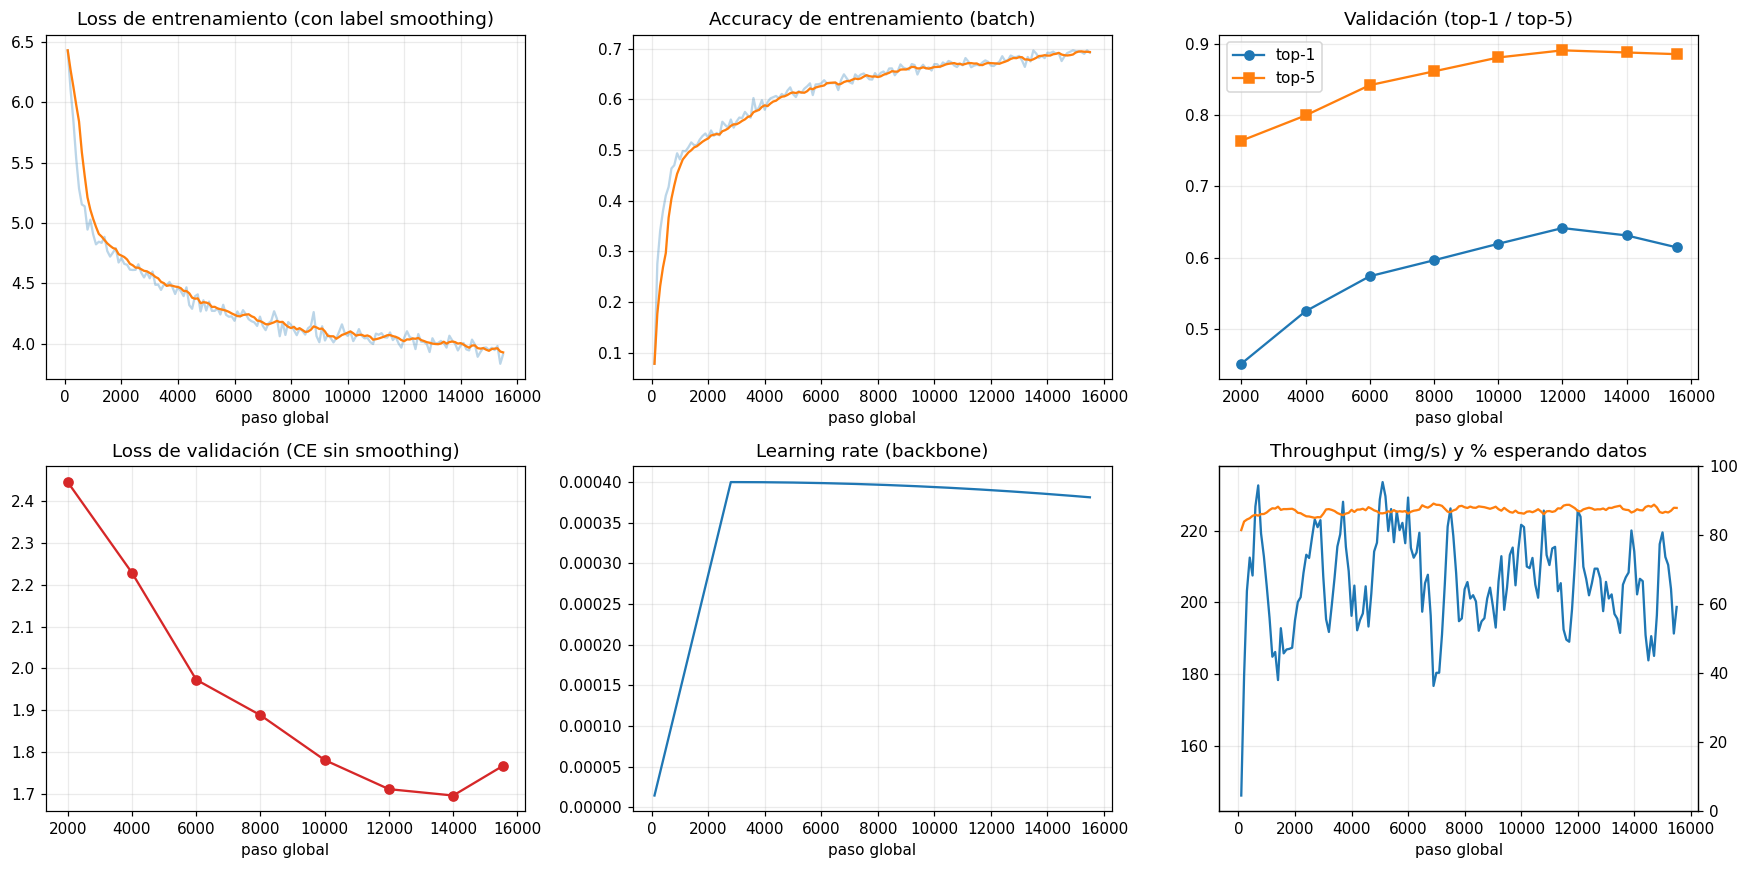

Pasos: 15,500 | throughput medio: 206 img/s | % esperando datos medio: 87%


In [ ]:
import matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# ---- curvas de entrenamiento ----
hist = json.load(open(DIR / "history.json")) if (DIR / "history.json").exists() else None
if hist and hist["train"]:
    tr = pd.DataFrame(hist["train"]); va = pd.DataFrame(hist["val"]) if hist["val"] else pd.DataFrame()
    sm = lambda s: s.rolling(5, min_periods=1).mean()
    fig, ax = plt.subplots(2, 3, figsize=(16, 8))
    ax[0, 0].plot(tr.step, tr.loss, alpha=.3); ax[0, 0].plot(tr.step, sm(tr.loss)); ax[0, 0].set_title("Loss de entrenamiento (con label smoothing)")
    ax[0, 1].plot(tr.step, tr.acc, alpha=.3); ax[0, 1].plot(tr.step, sm(tr.acc)); ax[0, 1].set_title("Accuracy de entrenamiento (batch)")
    if len(va):
        ax[0, 2].plot(va.step, va.top1, "o-", label="top-1"); ax[0, 2].plot(va.step, va.top5, "s-", label="top-5"); ax[0, 2].legend()
        ax[0, 2].set_title("Validación (top-1 / top-5)")
        ax[1, 0].plot(va.step, va.loss, "o-", color="tab:red"); ax[1, 0].set_title("Loss de validación (CE sin smoothing)")
    ax[1, 1].plot(tr.step, tr.lr); ax[1, 1].set_title("Learning rate (backbone)")
    ax[1, 2].plot(tr.step, sm(tr.img_s), label="img/s"); ax2 = ax[1, 2].twinx(); ax2.plot(tr.step, sm(tr.wait) * 100, color="tab:orange", label="% esperando datos")
    ax2.set_ylim(0, 100); ax[1, 2].set_title("Throughput (img/s) y % esperando datos"); ax2.grid(False)
    for a in ax.ravel(): a.set_xlabel("paso global")
    plt.tight_layout(); plt.savefig(OUT_DIR / "curvas_entrenamiento.png"); plt.show()
    print(f"Pasos: {tr.step.iloc[-1]:,} | throughput medio: {tr.img_s.mean():.0f} img/s | % esperando datos medio: {tr.wait.mean():.0%}")
else:
    print("Todavía no hay historial de entrenamiento.")

In [ ]:
# ---- predicciones sobre el val completo con el mejor checkpoint ----
def load_weights():
    for name in ["best.pt", "last.pt", "last_prev.pt"]:
        p = CKPT_DIR / name
        if p.exists():
            ck = torch.load(p, map_location="cpu", weights_only=False)
            assert ck["classes"] == classes, "Las clases del checkpoint no coinciden con meta.json"
            m = build_model(n_classes, pretrained=False); m.load_state_dict(ck["model"])
            print(f"Cargado {name} (paso {ck.get('step', ck.get('global_step', '?'))})")
            return m.to(device).to(memory_format=torch.channels_last).eval()
    raise FileNotFoundError("No hay checkpoints todavía: corré primero la celda de entrenamiento.")

eval_model = load_weights()
probs = predict_probs(eval_model, VAL["x"])                         # (N, C)
y_true = VAL["y"].numpy(); y_pred = probs.argmax(1); conf = probs.max(1)
val_df = pd.DataFrame(VAL["meta"], columns=["panoid", "lat", "lon", "true_cc"])
val_df["true_idx"] = y_true; val_df["pred_idx"] = y_pred
val_df["pred_cc"] = [classes[i] for i in y_pred]; val_df["conf"] = conf; val_df["p_true"] = probs[np.arange(len(y_true)), y_true]
val_df["correct"] = y_true == y_pred
val_df["true_cont"] = cont_of[y_true]; val_df["pred_cont"] = cont_of[y_pred]
val_df.to_csv(OUT_DIR / "val_predictions.csv", index=False)
print(f"N val = {len(val_df)} | accuracy top-1 = {val_df.correct.mean():.4f}")
val_df.head()

Cargado best.pt (paso 12000)
N val = 2996 | accuracy top-1 = 0.6419


,panoid,lat,lon,true_cc,true_idx,pred_idx,pred_cc,conf,p_true,correct,true_cont,pred_cont
0,hymmk6SxfZZngZeZzvBbpg,-9.414977,-59.112673,BR,11,11,BR,0.449129,0.449129,True,SA,SA
1,v5JLVR4RoJJM53p-xBH7oA,47.592294,21.873777,HU,36,81,RO,0.369744,0.228684,False,EU,EU
2,ip_sXJWNKU2CnOhqK9IG_g,-46.680520,-68.173661,AR,2,2,AR,0.652250,0.652250,True,SA,SA
3,jOt-v8F2mvh4pWO0liWdtA,60.961784,9.287152,NO,67,67,NO,0.792402,0.792402,True,EU,EU
4,baYa2xKec8n-Rbjsu0WgFw,64.086557,42.427839,RU,83,83,RU,0.293845,0.293845,True,EU,EU


In [ ]:
# ---- métricas globales ----
from sklearn.metrics import precision_recall_fscore_support, balanced_accuracy_score, f1_score

def haversine(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2); dl = np.radians(lon2 - lon1); dp = p2 - p1
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

def ece_score(conf, correct, bins=15):
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return e

order = np.argsort(-probs, axis=1)
topk = {k: float((order[:, :k] == y_true[:, None]).any(1).mean()) for k in (1, 3, 5, 10) if k <= n_classes}
present = np.unique(y_true)
dist_km = haversine(val_df.lat.values, val_df.lon.values, cent_lat[y_pred], cent_lon[y_pred])
M = {f"top-{k} accuracy": v for k, v in topk.items()}
M["balanced accuracy (recall medio por país)"] = balanced_accuracy_score(y_true, y_pred)
M["F1 macro"] = f1_score(y_true, y_pred, average="macro", labels=present, zero_division=0)
M["F1 ponderado"] = f1_score(y_true, y_pred, average="weighted", labels=present, zero_division=0)
M["NLL (log-loss)"] = float(-np.log(np.clip(probs[np.arange(len(y_true)), y_true], 1e-9, 1)).mean())
M["ECE (calibración, 15 bins)"] = ece_score(conf, val_df.correct.values)
M["confianza media"] = float(conf.mean())
M["accuracy a nivel continente"] = float((val_df.true_cont == val_df.pred_cont).mean())
M["distancia mediana al centroide del país predicho (km)"] = float(np.median(dist_km))
for t in (25, 200, 750, 2500):
    M[f"% con error < {t} km (vs centroide pred.)"] = float((dist_km < t).mean())
M_df = pd.DataFrame({"valor": M}); display(M_df.style.format("{:.4f}"))
print("Nota: la distancia usa el centroide del país predicho como punto de referencia, así que es una aproximación (países grandes penalizan).")

,valor
top-1 accuracy,0.6419
top-3 accuracy,0.8338
top-5 accuracy,0.8905
top-10 accuracy,0.9383
balanced accuracy (recall medio por país),0.4420
F1 macro,0.4032
F1 ponderado,0.6463
NLL (log-loss),1.7112
"ECE (calibración, 15 bins)",0.2735
confianza media,0.3684


Nota: la distancia usa el centroide del país predicho como punto de referencia, así que es una aproximación (países grandes penalizan).


,cc,name,continent,n_train,val_support,precision,recall,f1,pred_count
97,US,United States,NA,476840,605,0.80,0.75,0.77,567
41,IN,India,AS,266860,325,0.95,0.95,0.95,327
11,BR,Brazil,SA,136920,247,0.79,0.79,0.79,246
4,AU,Australia,OC,61304,133,0.81,0.75,0.78,123
14,CA,Canada,NA,63792,123,0.72,0.59,0.65,100
83,RU,Russian Federation,EU,55884,122,0.77,0.66,0.71,104
29,FR,France,EU,86208,82,0.49,0.37,0.42,61
62,MX,Mexico,NA,45260,82,0.52,0.45,0.48,71
37,ID,Indonesia,AS,48156,77,0.47,0.65,0.54,107
2,AR,Argentina,SA,29668,71,0.84,0.58,0.68,49


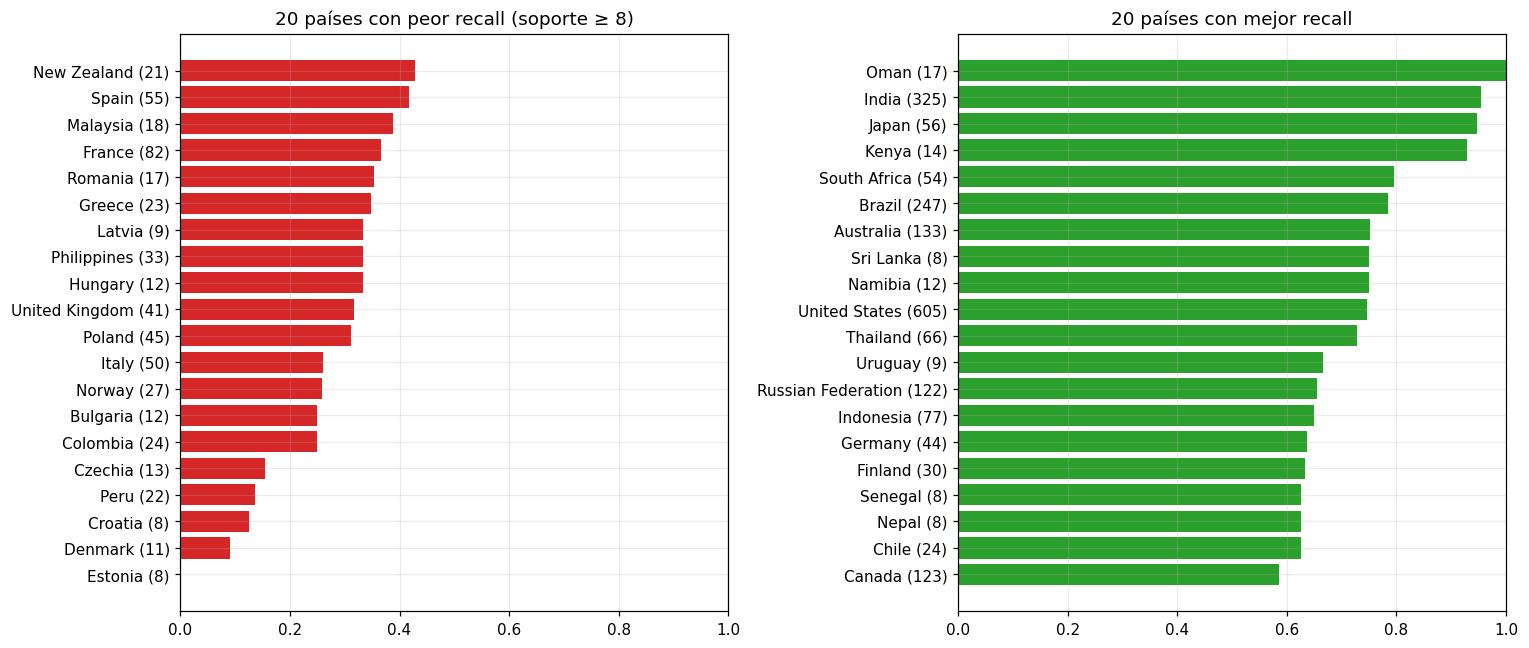

In [ ]:
# ---- métricas por país ----
p, r, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=np.arange(n_classes), zero_division=0)
per_country = class_info[["cc", "name", "continent", "n_train"]].copy()
per_country["val_support"] = sup; per_country["precision"] = p; per_country["recall"] = r; per_country["f1"] = f1
per_country["pred_count"] = np.bincount(y_pred, minlength=n_classes)
per_country = per_country[per_country.val_support > 0].sort_values("val_support", ascending=False)
per_country.to_csv(OUT_DIR / "metricas_por_pais.csv", index=False)
display(per_country.head(25).style.format({"precision": "{:.2f}", "recall": "{:.2f}", "f1": "{:.2f}"}))

MIN_SUP = 8
sub = per_country[per_country.val_support >= MIN_SUP].sort_values("recall")
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
w_ = sub.head(20); b_ = sub.tail(20)
ax[0].barh(w_.name + " (" + w_.val_support.astype(str) + ")", w_.recall, color="tab:red"); ax[0].set_title(f"20 países con peor recall (soporte ≥ {MIN_SUP})")
ax[1].barh(b_.name + " (" + b_.val_support.astype(str) + ")", b_.recall, color="tab:green"); ax[1].set_title("20 países con mejor recall")
for a in ax: a.set_xlim(0, 1)
plt.tight_layout(); plt.savefig(OUT_DIR / "recall_por_pais.png"); plt.show()

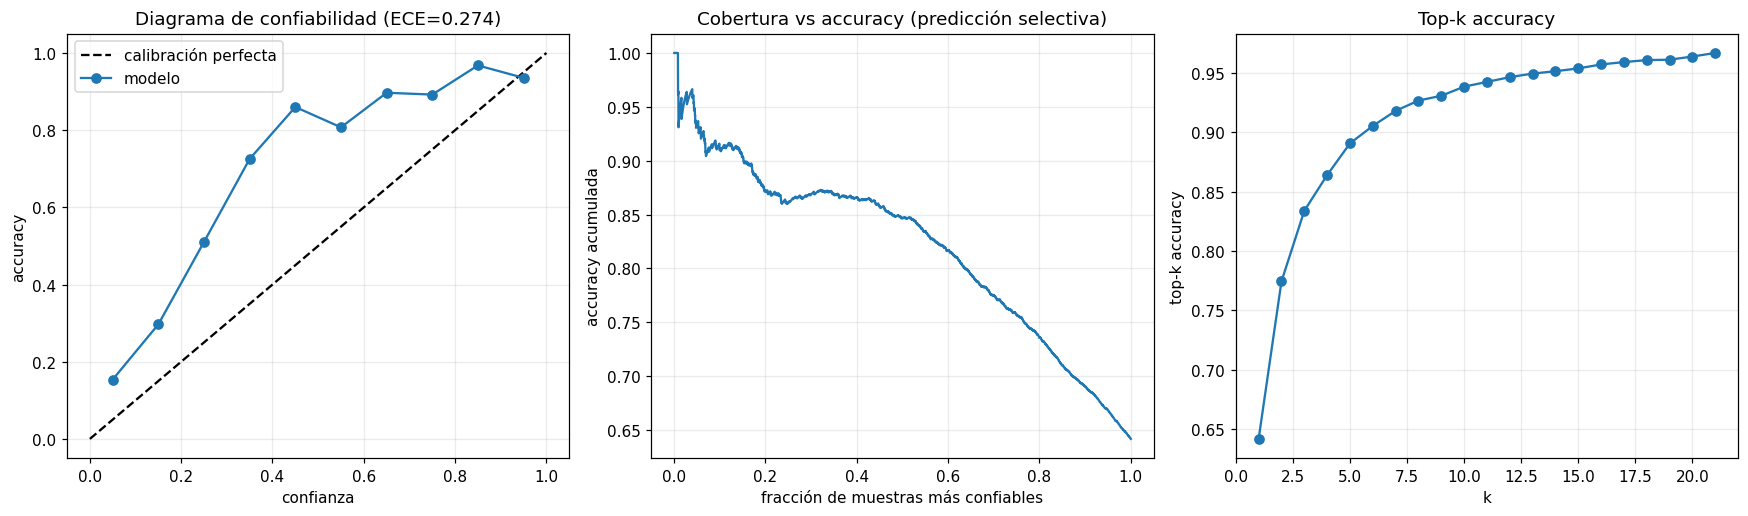

In [ ]:
# ---- calibración, cobertura-accuracy y top-k ----
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
edges = np.linspace(0, 1, 11); mids, accs, ns = [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (conf > lo) & (conf <= hi)
    if m.sum() >= 5: mids.append((lo + hi) / 2); accs.append(val_df.correct.values[m].mean()); ns.append(m.sum())
ax[0].plot([0, 1], [0, 1], "k--", label="calibración perfecta"); ax[0].plot(mids, accs, "o-", label="modelo")
ax[0].set_xlabel("confianza"); ax[0].set_ylabel("accuracy"); ax[0].set_title(f"Diagrama de confiabilidad (ECE={M['ECE (calibración, 15 bins)']:.3f})"); ax[0].legend()
o = np.argsort(-conf); cum = np.cumsum(val_df.correct.values[o]) / np.arange(1, len(o) + 1)
ax[1].plot(np.arange(1, len(o) + 1) / len(o), cum); ax[1].set_xlabel("fracción de muestras más confiables"); ax[1].set_ylabel("accuracy acumulada")
ax[1].set_title("Cobertura vs accuracy (predicción selectiva)")
ks = [k for k in range(1, min(21, n_classes) + 1)]
ax[2].plot(ks, [(order[:, :k] == y_true[:, None]).any(1).mean() for k in ks], "o-"); ax[2].set_xlabel("k"); ax[2].set_ylabel("top-k accuracy"); ax[2].set_title("Top-k accuracy")
plt.tight_layout(); plt.savefig(OUT_DIR / "calibracion_topk.png"); plt.show()

### Matrices de confusión
Primero a nivel **continente**, después **país por país dentro de cada continente** (los países más frecuentes en val; la columna `Otros` agrupa las predicciones que cayeron fuera de esa lista, incluidos otros continentes), y por último los países globales más frecuentes.

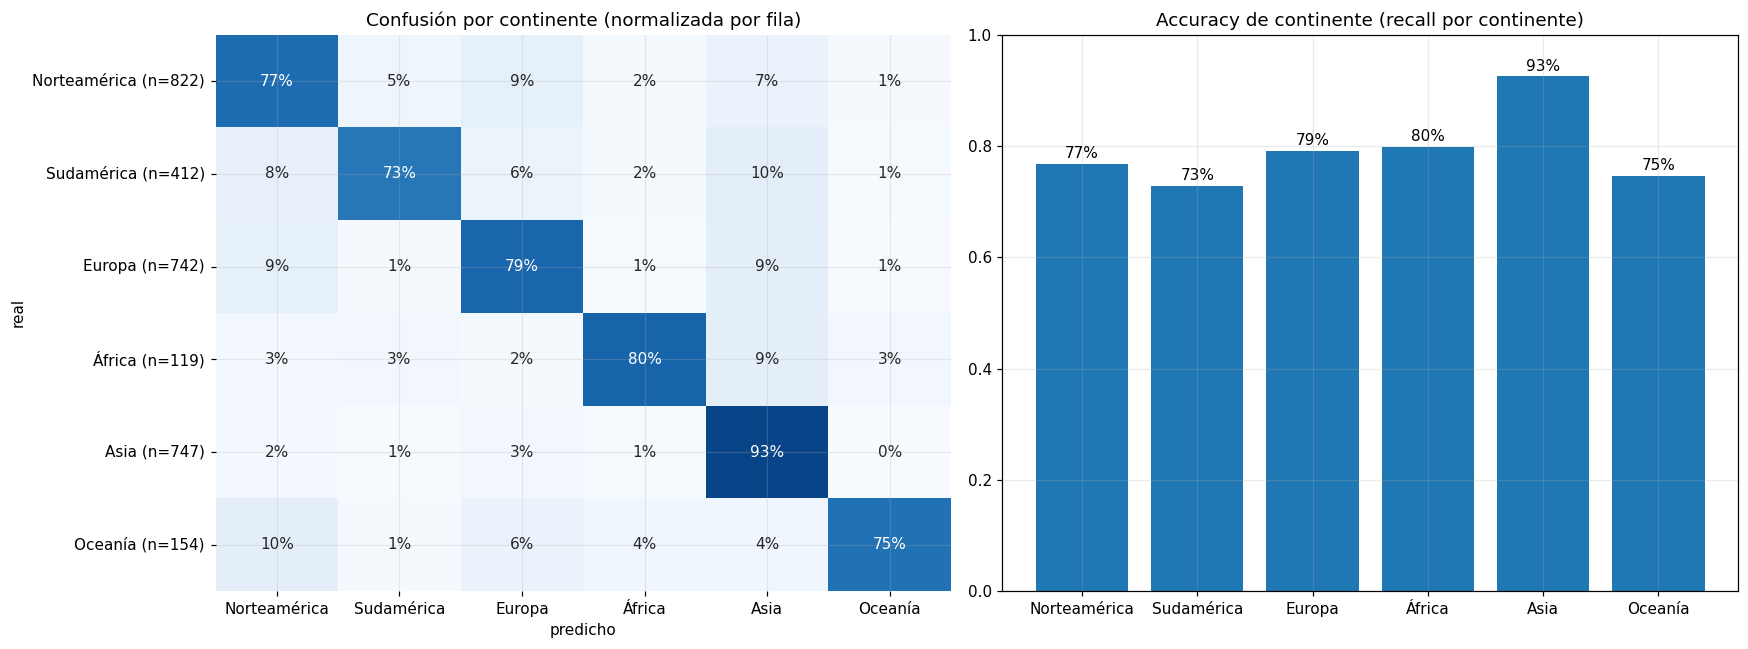

In [ ]:
# ---- confusión a nivel continente ----
conts = [c for c in ["NA", "SA", "EU", "AF", "AS", "OC", "AN"] if (val_df.true_cont == c).any() or (val_df.pred_cont == c).any()]
cm = pd.crosstab(val_df.true_cont, val_df.pred_cont).reindex(index=conts, columns=conts, fill_value=0)
cmn = cm.div(cm.sum(1).replace(0, np.nan), axis=0)
labels_y = [f"{CONT_NAMES[c]} (n={cm.loc[c].sum()})" for c in conts]; labels_x = [CONT_NAMES[c] for c in conts]
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cmn, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, xticklabels=labels_x, yticklabels=labels_y, ax=ax[0], cbar=False)
ax[0].set_title("Confusión por continente (normalizada por fila)"); ax[0].set_xlabel("predicho"); ax[0].set_ylabel("real")
rec_c = pd.Series({c: cm.loc[c, c] / cm.loc[c].sum() for c in conts if cm.loc[c].sum() > 0})
ax[1].bar([CONT_NAMES[c] for c in rec_c.index], rec_c.values, color="tab:blue"); ax[1].set_ylim(0, 1); ax[1].set_title("Accuracy de continente (recall por continente)")
for i, v in enumerate(rec_c.values): ax[1].text(i, v + .01, f"{v:.0%}", ha="center")
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_continentes.png"); plt.show()

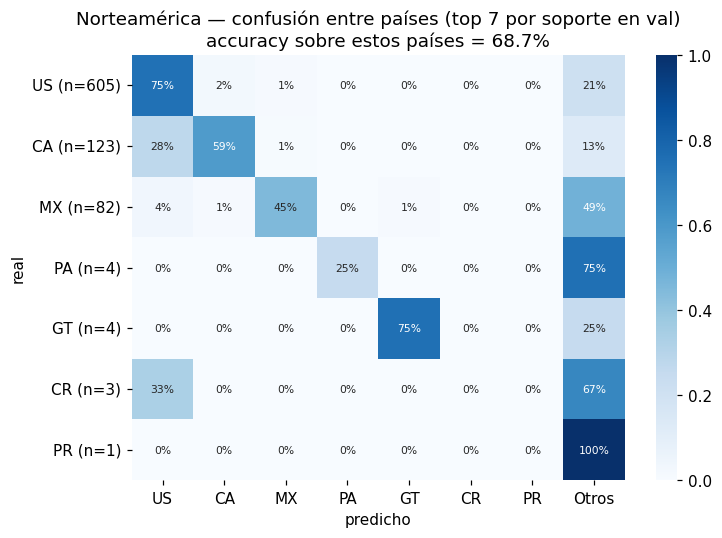

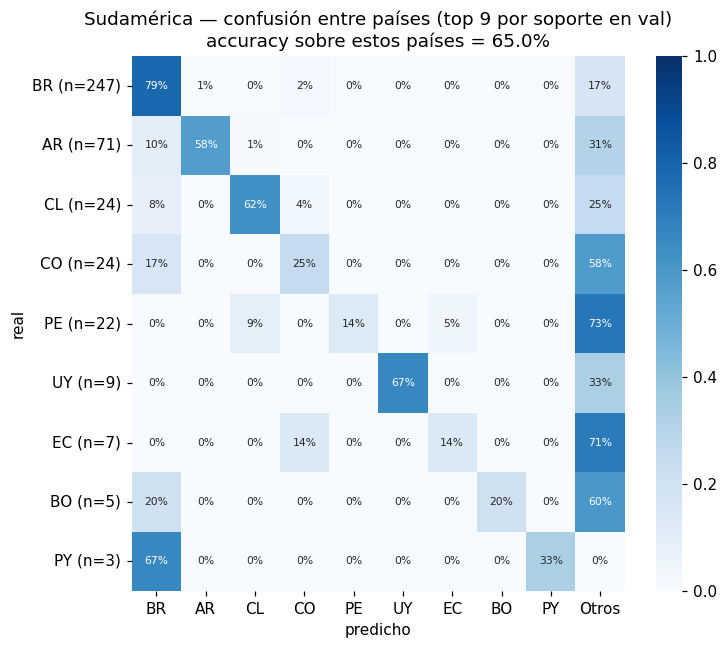

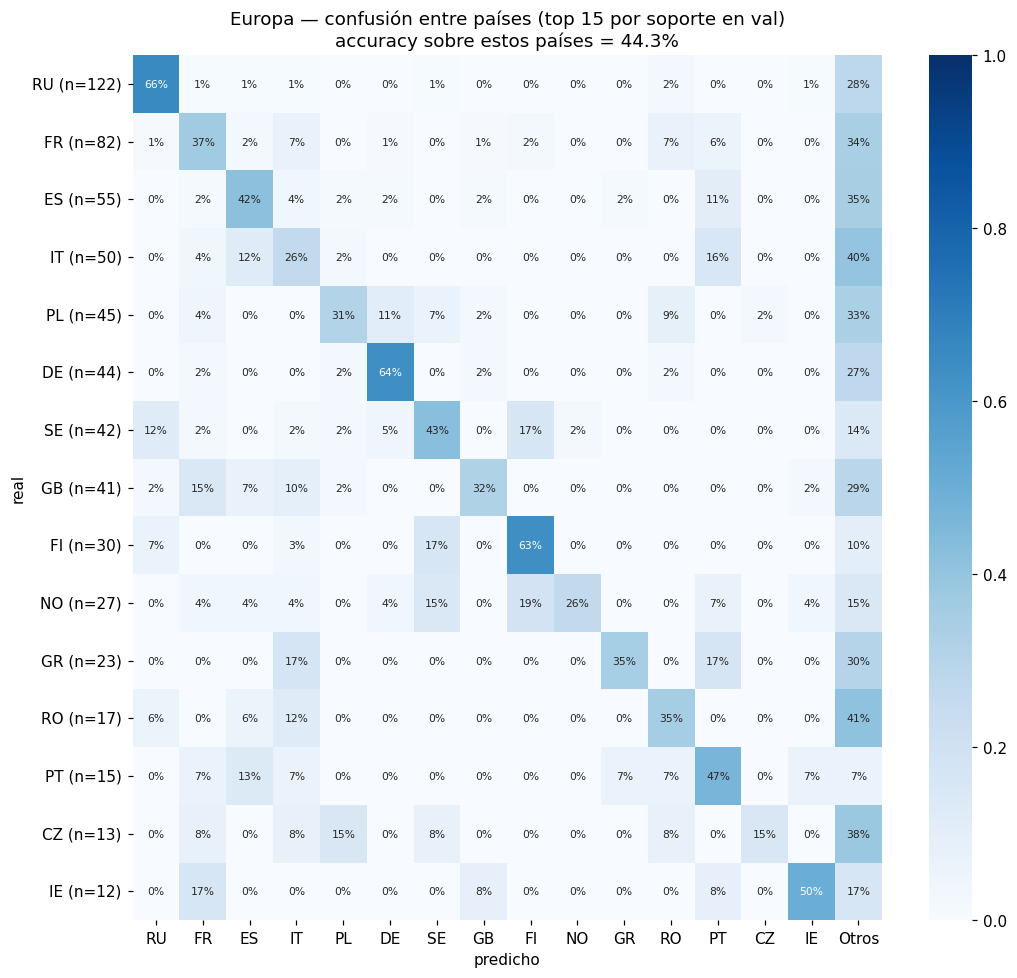

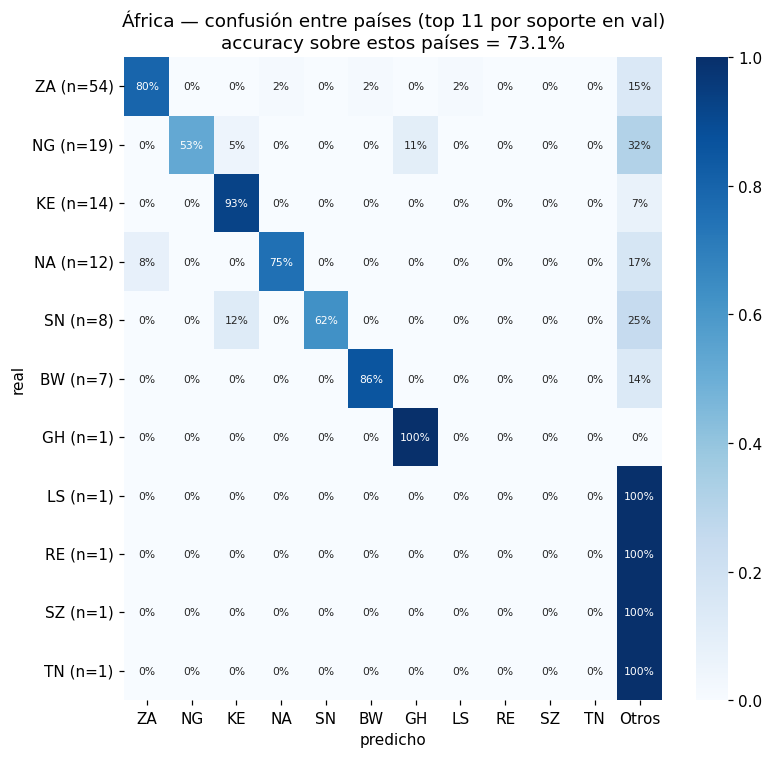

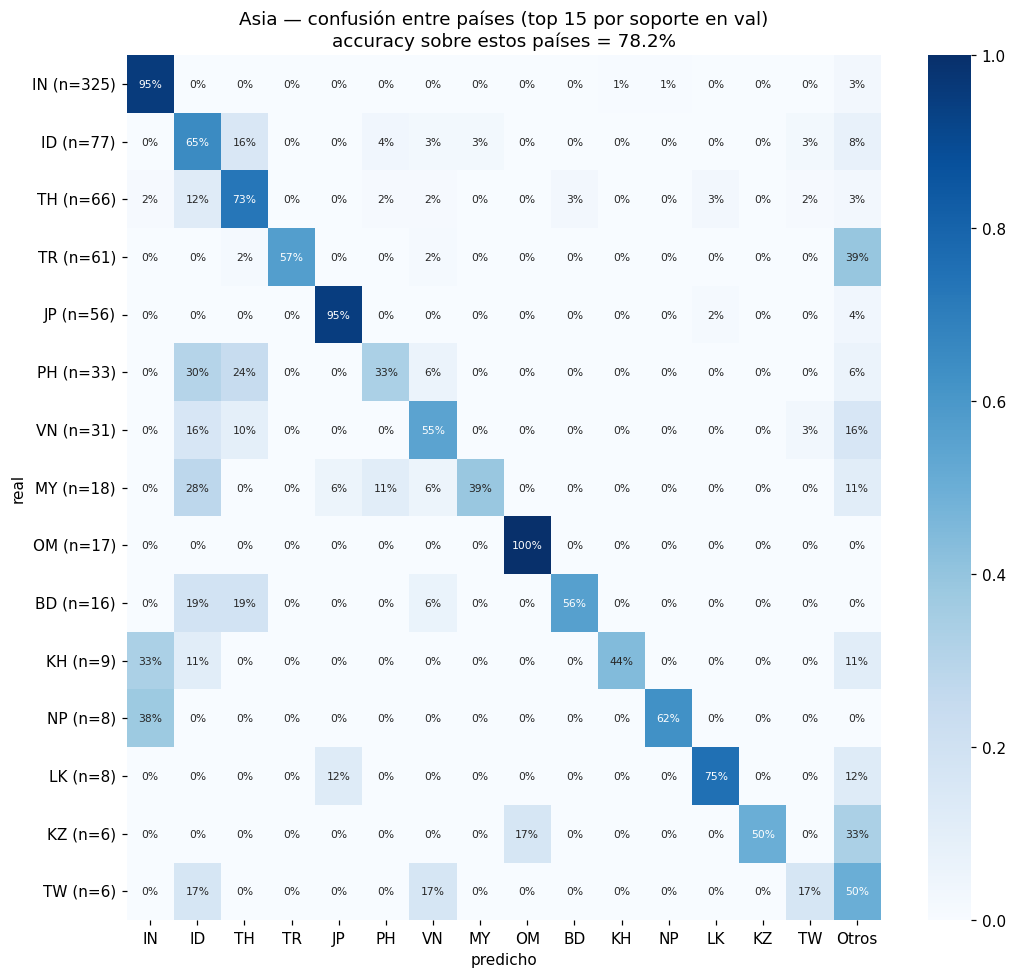

Oceanía: solo 2 países en val, se omite
Matrices completas (CSV) en: /content/drive/MyDrive/streetview_country_resnet18/outputs/confusion_por_continente


In [ ]:
# ---- confusión país por país DENTRO de cada continente ----
TOP_N = 15          # países por continente en cada matriz
MIN_COUNTRIES = 3   # no graficar continentes con menos países que esto en val

def country_cm(true_idx_set, y_true, y_pred):
    pos = {c: i for i, c in enumerate(true_idx_set)}
    M_ = np.zeros((len(true_idx_set), len(true_idx_set) + 1))
    for t, pr in zip(y_true, y_pred):
        if t in pos:
            M_[pos[t], pos[pr] if pr in pos else len(true_idx_set)] += 1
    return M_

full_dir = OUT_DIR / "confusion_por_continente"; full_dir.mkdir(exist_ok=True)
for c in conts:
    idxs = per_country[per_country.continent == c].sort_values("val_support", ascending=False)
    if len(idxs) < MIN_COUNTRIES:
        print(f"{CONT_NAMES[c]}: solo {len(idxs)} países en val, se omite"); continue
    sel = [class2idx[cc] for cc in idxs.head(TOP_N).cc]
    Mc = country_cm(sel, y_true, y_pred); rows = Mc.sum(1, keepdims=True)
    Mn = np.divide(Mc, rows, out=np.zeros_like(Mc), where=rows > 0)
    names = [classes[i] for i in sel]
    fig, ax = plt.subplots(figsize=(max(7, 0.62 * (len(sel) + 1)), max(5, 0.5 * len(sel) + 1.5)))
    sns.heatmap(Mn, annot=len(sel) <= 16, fmt=".0%", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=True,
                xticklabels=names + ["Otros"], yticklabels=[f"{n} (n={int(r)})" for n, r in zip(names, rows[:, 0])], annot_kws={"size": 7})
    acc_c = np.trace(Mc[:, :len(sel)]) / max(Mc.sum(), 1)
    ax.set_title(f"{CONT_NAMES[c]} — confusión entre países (top {len(sel)} por soporte en val)\n"
                 f"accuracy sobre estos países = {acc_c:.1%}"); ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.grid(False)
    plt.tight_layout(); plt.savefig(full_dir / f"confusion_{c}.png"); plt.show()
    # matriz completa del continente (todos los países, sin recortar) a CSV
    all_idx = [class2idx[cc] for cc in idxs.cc]; Mfull = country_cm(all_idx, y_true, y_pred)
    pd.DataFrame(Mfull, index=[classes[i] for i in all_idx], columns=[classes[i] for i in all_idx] + ["Otros"]).to_csv(full_dir / f"confusion_{c}.csv")
print("Matrices completas (CSV) en:", full_dir)

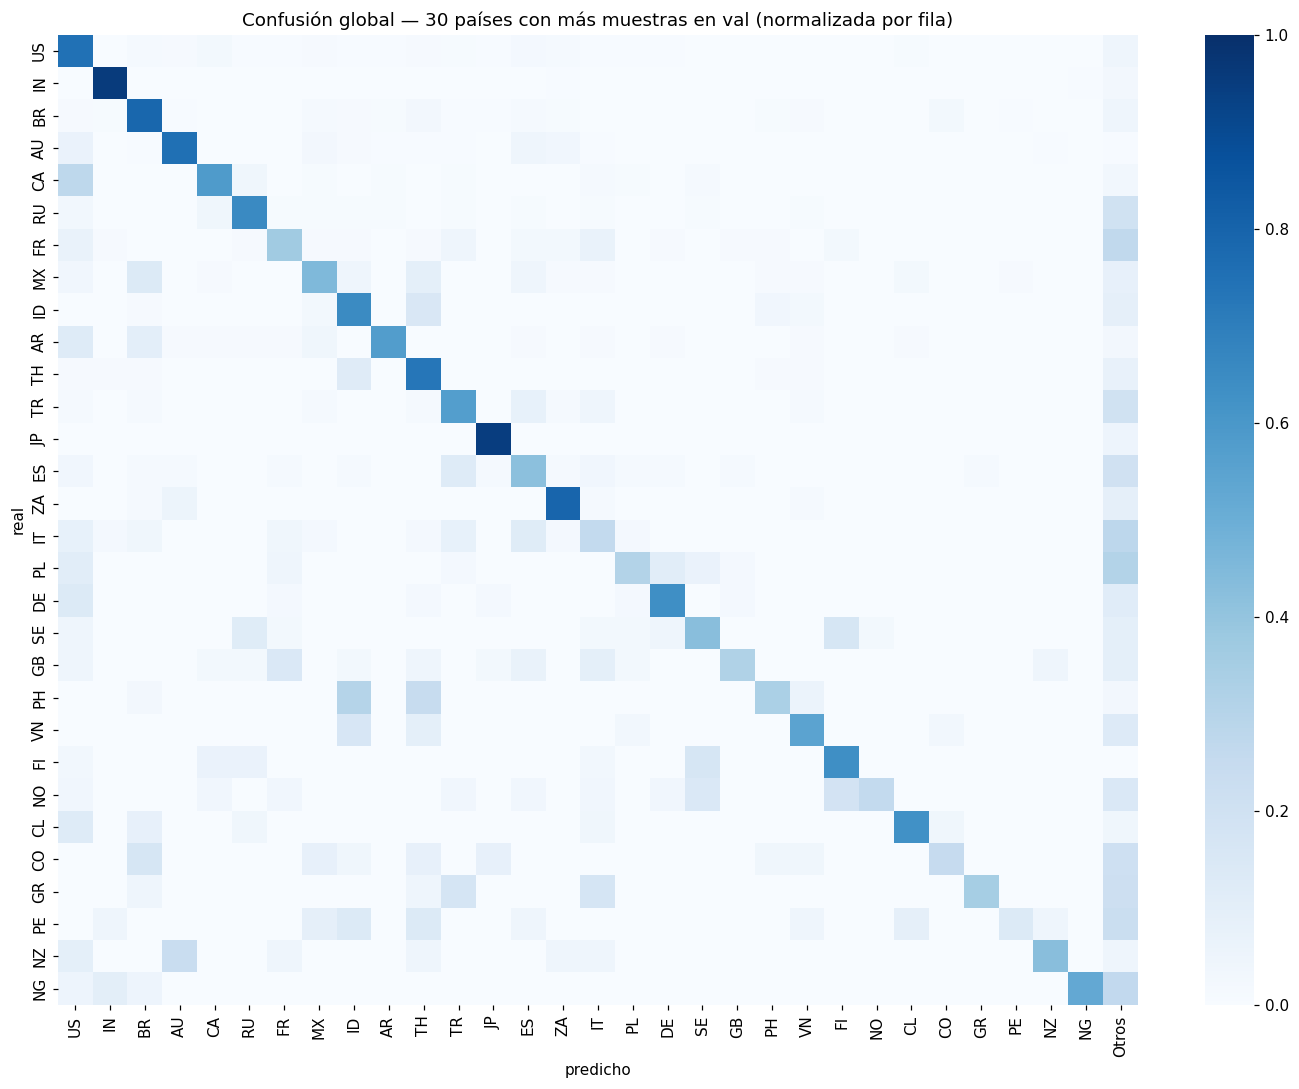

,real,predicho,n,% de la clase real,mismo continente
88,Canada,United States,34,28%,True
497,United States,Canada,15,2%,True
500,United States,Spain,14,2%,False
236,Indonesia,Thailand,12,16%,True
298,Mexico,Brazil,11,13%,False
496,United States,Brazil,10,2%,False
369,Philippines,Indonesia,10,30%,True
532,United States,South Africa,10,2%,False
13,Argentina,United States,9,13%,False
494,United States,Australia,9,1%,False


Errores dentro del mismo continente: 46.2% de los errores


In [ ]:
# ---- confusión global: top-30 países por soporte + pares más confundidos ----
top = per_country.head(30); sel = [class2idx[cc] for cc in top.cc]
Mc = country_cm(sel, y_true, y_pred); rows = Mc.sum(1, keepdims=True); Mn = np.divide(Mc, rows, out=np.zeros_like(Mc), where=rows > 0)
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(Mn, cmap="Blues", vmin=0, vmax=1, ax=ax, xticklabels=list(top.cc) + ["Otros"], yticklabels=list(top.cc), cbar=True)
ax.set_title("Confusión global — 30 países con más muestras en val (normalizada por fila)"); ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.grid(False)
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_top30.png"); plt.show()

err = val_df[~val_df.correct]
pairs = err.groupby(["true_cc", "pred_cc"]).size().reset_index(name="n").sort_values("n", ascending=False)
sup_map = per_country.set_index("cc").val_support
pairs["% de la clase real"] = pairs.apply(lambda r_: r_.n / sup_map.get(r_.true_cc, np.nan), axis=1)
pairs["real"] = pairs.true_cc.map(cname); pairs["predicho"] = pairs.pred_cc.map(cname)
pairs["mismo continente"] = pairs.true_cc.map(lambda c_: cont_of[class2idx[c_]]) == pairs.pred_cc.map(lambda c_: cont_of[class2idx[c_]])
display(pairs.head(25)[["real", "predicho", "n", "% de la clase real", "mismo continente"]].style.format({"% de la clase real": "{:.0%}"}))
print(f"Errores dentro del mismo continente: {(err.true_cont == err.pred_cont).mean():.1%} de los errores")

### Mapas de error
Interactivos (plotly). También se guardan como HTML en `outputs/mapas/`.

In [ ]:
import plotly.express as px, plotly.graph_objects as go
MAP_DIR = OUT_DIR / "mapas"; MAP_DIR.mkdir(exist_ok=True)

# 1) cada imagen de val sobre su ubicación real: acierto / error
d = val_df.copy()
d["resultado"] = np.where(d.correct, "✔ acierto", "✘ error")
d["real"] = d.true_cc.map(cname); d["predicho"] = d.pred_cc.map(cname); d["conf"] = d.conf.round(2)
fig = px.scatter_geo(d.sort_values("correct"), lat="lat", lon="lon", color="resultado", opacity=0.75,
                     color_discrete_map={"✔ acierto": "#2ca02c", "✘ error": "#d62728"},
                     hover_data={"real": True, "predicho": True, "conf": True, "lat": False, "lon": False},
                     projection="natural earth", title=f"Val: aciertos y errores sobre la ubicación real (accuracy {d.correct.mean():.1%})")
fig.update_traces(marker_size=5); fig.update_layout(height=560, margin=dict(l=0, r=0, t=50, b=0)); fig.write_html(MAP_DIR / "val_aciertos_errores.html"); fig.show()

# 2) distancia del error (km al centroide del país predicho), solo errores
e = d[~d.correct].copy(); e["dist_km"] = haversine(e.lat.values, e.lon.values, cent_lat[e.pred_idx.values], cent_lon[e.pred_idx.values])
fig = px.scatter_geo(e, lat="lat", lon="lon", color=np.log10(e.dist_km.clip(lower=1)), color_continuous_scale="Turbo", projection="natural earth",
                     hover_data={"real": True, "predicho": True, "dist_km": ":.0f", "lat": False, "lon": False},
                     title="Errores de val coloreados por distancia (log10 km) al centroide del país predicho", labels={"color": "log10 km"})
fig.update_traces(marker_size=6); fig.update_layout(height=560, margin=dict(l=0, r=0, t=50, b=0)); fig.write_html(MAP_DIR / "val_distancia_error.html"); fig.show()

# 3) mapa por país: tasa de error (1 - recall) con soporte mínimo
MIN_SUP_MAP = 5
pc = per_country[per_country.val_support >= MIN_SUP_MAP].merge(class_info[["cc", "iso3"]], on="cc")
pc = pc[pc.iso3.notna()].copy(); pc["error_rate"] = 1 - pc["recall"]
fig = px.choropleth(pc, locations="iso3", color="error_rate", color_continuous_scale="RdYlGn_r", range_color=(0, 1),
                    hover_name="name", hover_data={"iso3": False, "val_support": True, "recall": ":.2f", "precision": ":.2f", "n_train": True, "error_rate": ":.2f"},
                    projection="natural earth", title=f"Tasa de error por país (1 − recall) — países con ≥ {MIN_SUP_MAP} muestras en val")
fig.update_layout(height=560, margin=dict(l=0, r=0, t=50, b=0)); fig.write_html(MAP_DIR / "error_por_pais.html"); fig.show()

# 4) burbujas sobre el centroide: tamaño = soporte en val, color = tasa de error
bub = per_country.merge(class_info[["cc", "lat", "lon"]], on="cc"); bub["error_rate"] = 1 - bub.recall
fig = px.scatter_geo(bub, lat="lat", lon="lon", size="val_support", color="error_rate", color_continuous_scale="RdYlGn_r", range_color=(0, 1),
                     hover_name="name", hover_data={"val_support": True, "error_rate": ":.2f", "n_train": True, "lat": False, "lon": False},
                     projection="natural earth", size_max=28, title="Error por país (burbuja = muestras en val)")
fig.update_layout(height=560, margin=dict(l=0, r=0, t=50, b=0)); fig.write_html(MAP_DIR / "error_burbujas.html"); fig.show()

# 5) cobertura del train por país (sesgo geográfico del dataset)
ci = class_info[class_info.iso3.notna()].copy(); ci["log10_imgs"] = np.log10(ci.n_train)
fig = px.choropleth(ci, locations="iso3", color="log10_imgs", color_continuous_scale="Viridis", hover_name="name", hover_data={"n_train": True, "iso3": False, "log10_imgs": False},
                    projection="natural earth", title="Imágenes de entrenamiento por país (log10)")
fig.update_layout(height=520, margin=dict(l=0, r=0, t=50, b=0)); fig.write_html(MAP_DIR / "cobertura_train.html"); fig.show()

# 6) "flujos": a qué país se confunde cada país con más error (líneas del centroide real al predicho)
big = pairs[pairs.n >= 2].head(40)
fig = go.Figure()
for _, rr in big.iterrows():
    i, j = class2idx[rr.true_cc], class2idx[rr.pred_cc]
    fig.add_trace(go.Scattergeo(lon=[cent_lon[i], cent_lon[j]], lat=[cent_lat[i], cent_lat[j]], mode="lines",
                                line=dict(width=0.8 + rr.n * 0.6, color="rgba(214,39,40,0.55)"), hoverinfo="text",
                                text=f"{rr.real} → {rr.predicho}: {rr.n} errores", showlegend=False))
fig.update_layout(title="Confusiones más frecuentes (real → predicho), ≥ 2 errores", geo=dict(projection_type="natural earth", showcountries=True, countrycolor="lightgray"),
                  height=560, margin=dict(l=0, r=0, t=50, b=0))
fig.write_html(MAP_DIR / "flujos_confusion.html"); fig.show()
print("HTML guardados en", MAP_DIR)

HTML guardados en /content/drive/MyDrive/streetview_country_resnet18/outputs/mapas


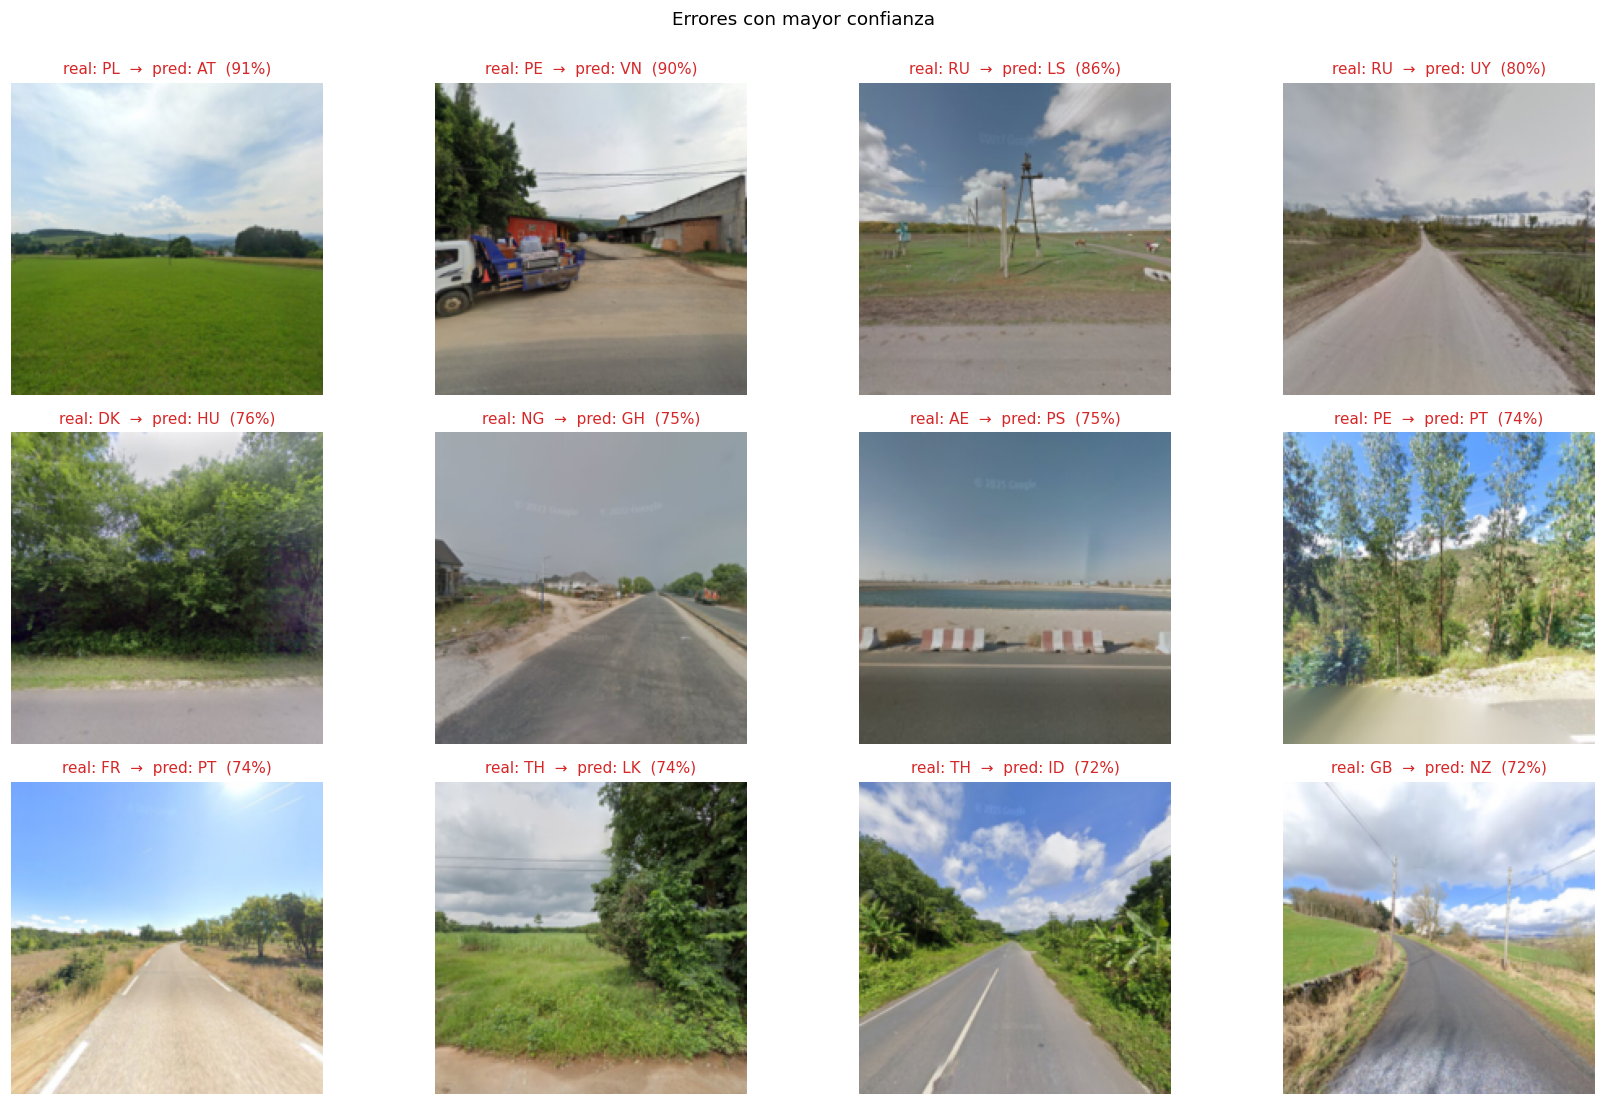

In [ ]:
# ---- galería: errores más "seguros" del modelo (las imágenes que más lo engañan) ----
worst = val_df[~val_df.correct].sort_values("conf", ascending=False).head(12)
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, (i, rr) in zip(axes.ravel(), worst.iterrows()):
    ax.imshow(VAL["x"][i].numpy()); ax.axis("off")
    ax.set_title(f"real: {rr.true_cc}  →  pred: {rr.pred_cc}  ({rr.conf:.0%})", fontsize=10, color="tab:red")
plt.suptitle("Errores con mayor confianza", y=1.0); plt.tight_layout(); plt.savefig(OUT_DIR / "galeria_errores.png"); plt.show()

## 4) Exportar el modelo e inferir sobre una imagen
Genera `modelo_final.pt` (pesos + lista de países + tamaño de entrada) en tu Drive, listo para cargar en otro entorno.

In [ ]:
best_path = CKPT_DIR / "best.pt" if (CKPT_DIR / "best.pt").exists() else CKPT_DIR / "last.pt"
ck = torch.load(best_path, map_location="cpu", weights_only=False)
torch.save({"model_state_dict": ck["model"], "classes": classes, "img_size": CFG.IMG_SIZE,
            "mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225], "arch": "resnet18"}, DIR / "modelo_final.pt")
print("Exportado:", DIR / "modelo_final.pt", "(desde", best_path.name + ")")

def predict_pil(img, k=5, model=None):
    # img: PIL.Image. Devuelve los top-k (país, probabilidad)
    model = model or eval_model
    a = np.asarray(img.convert("RGB").resize((CFG.IMG_SIZE, CFG.IMG_SIZE), PILImage.BILINEAR), dtype=np.uint8)[None]
    p_ = predict_probs(model, torch.from_numpy(a))[0]
    top_ = p_.argsort()[::-1][:k]
    return [(classes[i], cname(classes[i]), float(p_[i])) for i in top_]

# ejemplo con una imagen de val
print(predict_pil(PILImage.fromarray(VAL["x"][0].numpy())), "| real:", val_df.true_cc[0])

Exportado: /content/drive/MyDrive/streetview_country_resnet18/modelo_final.pt (desde best.pt)
[('BR', 'Brazil', 0.44912320375442505), ('AR', 'Argentina', 0.023309528827667236), ('PS', 'Palestine, State of', 0.020412996411323547), ('LB', 'Lebanon', 0.018635088577866554), ('LU', 'Luxembourg', 0.017270440235733986)] | real: BR
